# Explore features for model 2

Model 2 describes each 3 s window with many numbers from all six IMU channels.
The feature code lives in `python/features.py` so the board computes exactly
the same thing. This notebook checks which features are worth keeping.

1. Load recordings and compute features per window
2. Distributions by class
3. Ranking: how well each feature separates bike from walk, and how much it
   drifts between sessions

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../../python")
from features import FS, NAMES, features, spectrum

DATA_DIR = Path("../../data")
CLASSES = ["still", "bike", "walk", "run"]
COLS = ["ax", "ay", "az", "gx", "gy", "gz"]
WIN_S = 3.0
TRIM_S = 5.0

## 1. Features per window

In [2]:
n = int(WIN_S * FS)
rows = []
for p in sorted(DATA_DIR.glob("*.csv")):
    df = pd.read_csv(p)
    t = (df.t_ms - df.t_ms.iloc[0]) / 1000.0
    x = df.loc[(t >= TRIM_S) & (t <= t.iloc[-1] - TRIM_S), COLS].to_numpy()
    for i in range(0, len(x) - n + 1, n // 2):
        rows.append({"rec": p.stem, "label": p.stem.rsplit("_", 1)[0], **features(x[i:i + n])})
feat = pd.DataFrame(rows)
print(feat.groupby("rec").size().to_string())
feat.groupby("label")[NAMES].median().reindex(CLASSES).T.round(3)

rec
bike_01      45
bike_02      48
run_01       34
still_01     75
walk_01     182
walk_02      60


label,still,bike,walk,run
stride_hz,2.100,1.270,1.660,1.465
rhythm,0.047,0.785,0.266,0.519
std_ax,0.007,0.585,0.445,1.339
std_ay,0.004,0.631,0.527,1.291
std_az,0.010,0.319,0.380,0.918
std_gx,0.860,46.220,52.536,36.717
std_gy,0.875,32.281,59.880,136.061
std_gz,0.475,141.600,147.988,151.643
range_amag,0.031,1.876,2.810,7.531
range_gmag,5.493,219.362,326.101,442.965


### Example spectra

The FFT of `ay` for one window of each class. The tallest bar in the shaded
band is `dom_hz`; the share of power near it is `rhythm`.

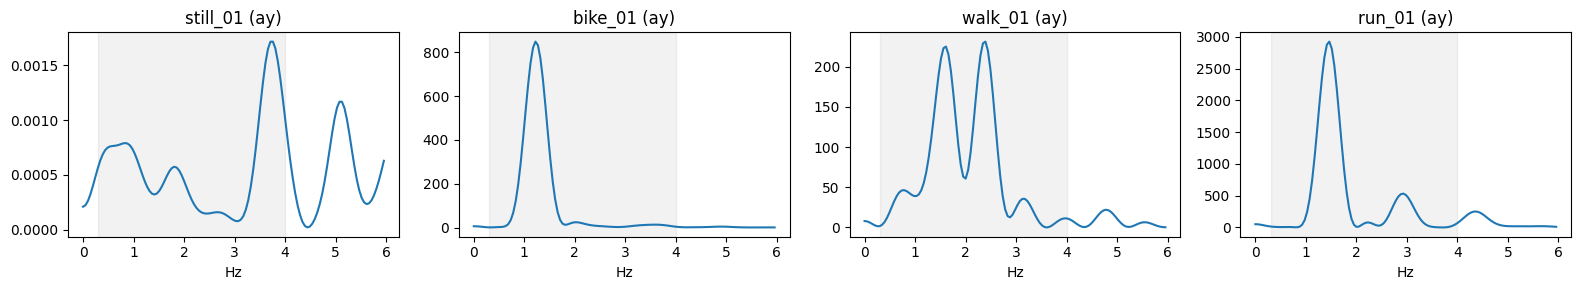

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3), sharey=False)
for ax, c in zip(axs, CLASSES):
    rec = sorted(feat[feat.label == c].rec.unique())[0]
    df = pd.read_csv(DATA_DIR / f"{rec}.csv")
    mid = len(df) // 2
    freqs, power = spectrum(df.ay.to_numpy()[mid:mid + n])
    keep = freqs <= 6
    ax.plot(freqs[keep], power[keep])
    ax.axvspan(0.3, 4.0, color="grey", alpha=0.1)
    ax.set_title(f"{rec} (ay)")
    ax.set_xlabel("Hz")
fig.tight_layout()

## 2. Distributions by class

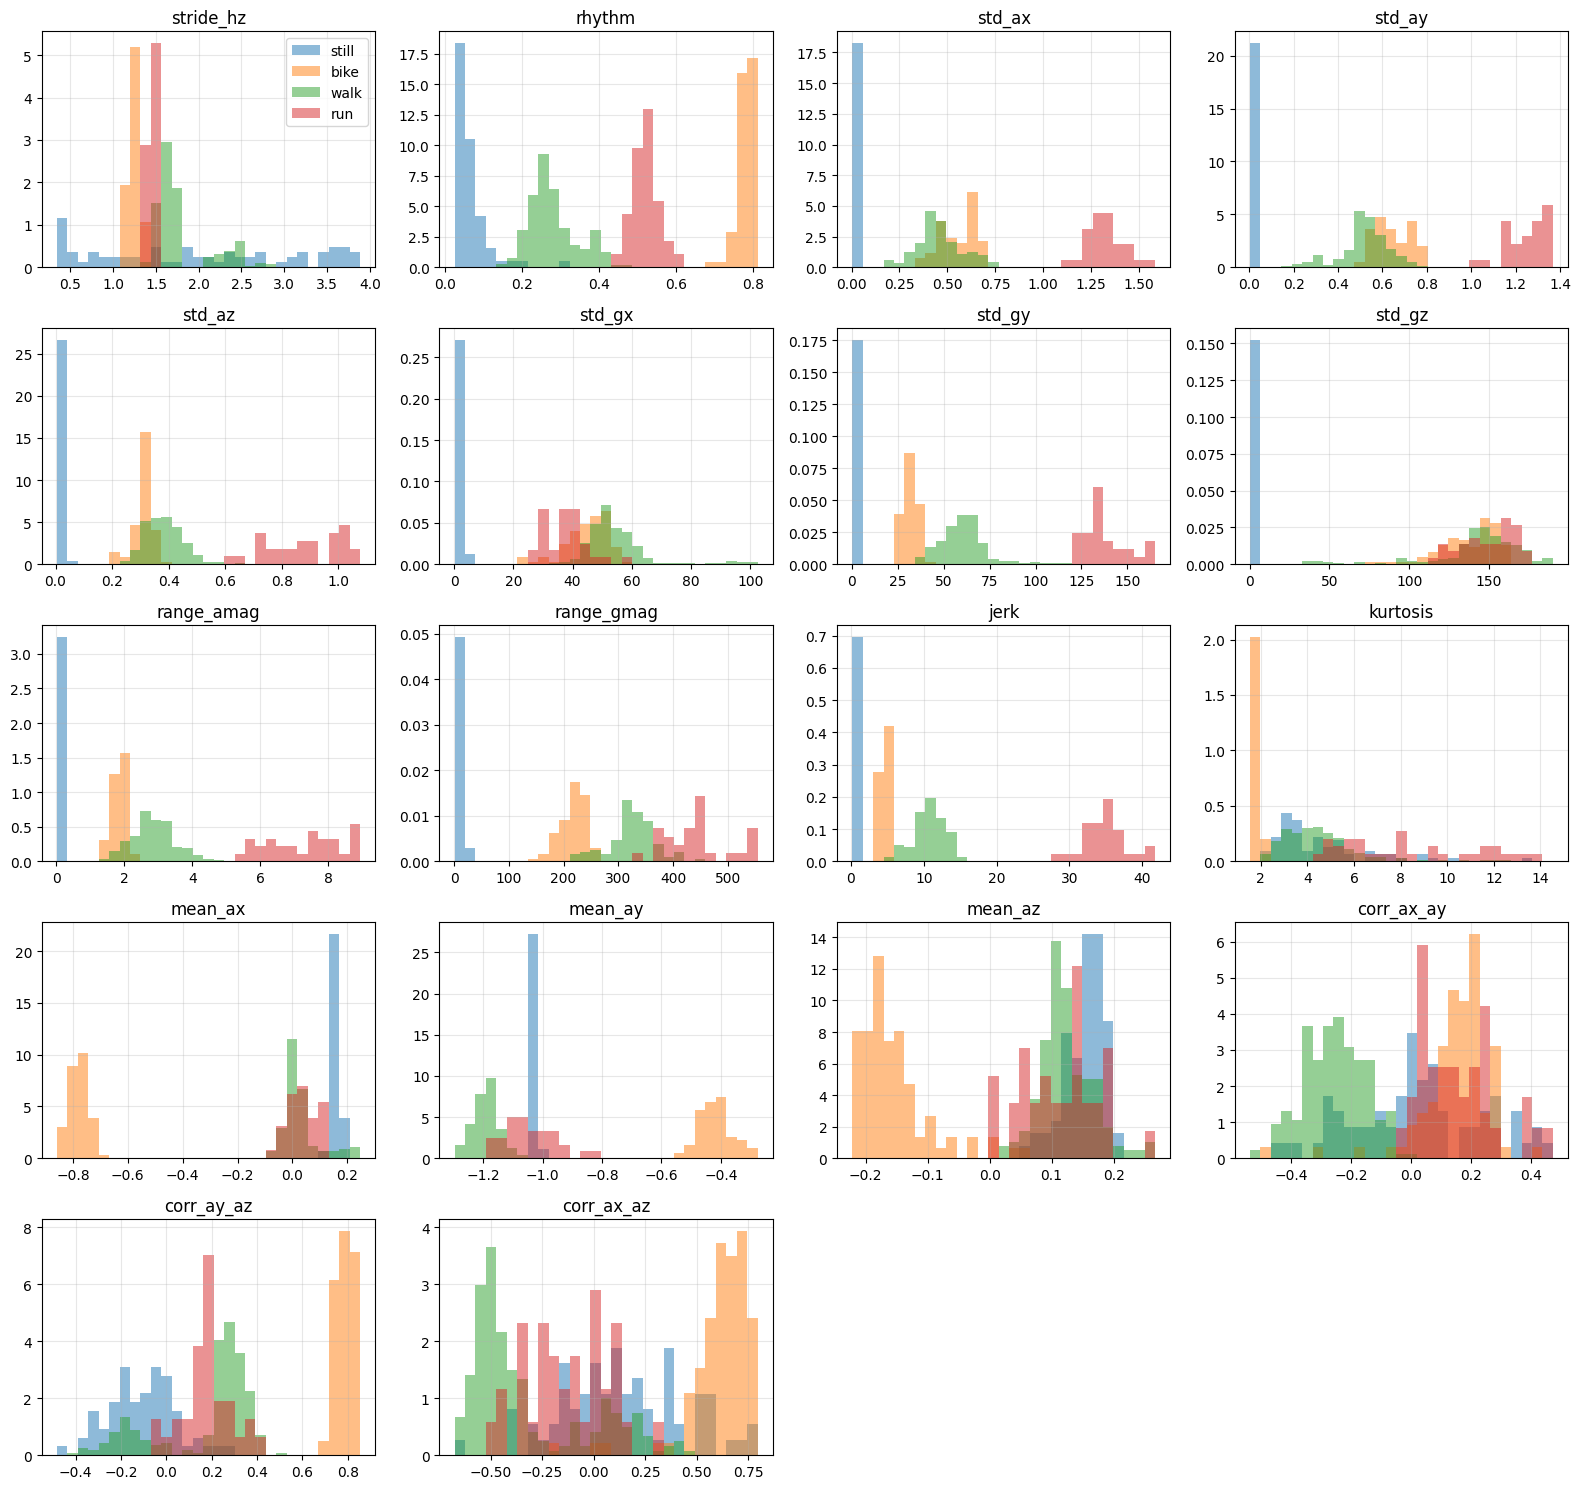

In [4]:
cols = 4
rows_n = int(np.ceil(len(NAMES) / cols))
fig, axs = plt.subplots(rows_n, cols, figsize=(16, 3 * rows_n))
for ax, name in zip(axs.flat, NAMES):
    lo, hi = feat[name].quantile([0.01, 0.99])
    bins = np.linspace(lo, hi, 30) if hi > lo else 10
    for c in CLASSES:
        ax.hist(feat.loc[feat.label == c, name], bins=bins, alpha=0.5, density=True, label=c)
    ax.set_title(name)
    ax.grid(alpha=0.3)
for ax in axs.flat[len(NAMES):]:
    ax.axis("off")
axs.flat[0].legend()
fig.tight_layout()

## 3. Ranking

- **bike vs walk AUC**: chance that a random walk window and a random bike
  window are put in the right order by this feature alone. 0.5 = useless,
  1.0 = perfect separation.
- **session drift**: how far the bike and walk medians move between `_01` and
  `_02`, in units of the feature's spread. Above ~1 means the feature changes a
  lot from day to day and may not hold up.

In [5]:
def auc(a, b):
    """Separation of two samples, 0.5..1, direction ignored."""
    ranks = pd.concat([pd.Series(a), pd.Series(b)]).rank().to_numpy()
    u = ranks[:len(a)].sum() - len(a) * (len(a) + 1) / 2
    score = u / (len(a) * len(b))
    return max(score, 1 - score)


bw = feat[feat.label.isin(["bike", "walk"])]
rank = []
for name in NAMES:
    spread = bw[name].std() or 1.0
    drift = max(abs(feat.loc[feat.rec == f"{c}_01", name].median() -
                    feat.loc[feat.rec == f"{c}_02", name].median()) / spread
                for c in ("bike", "walk"))
    rank.append({"feature": name,
                 "bike_vs_walk_auc": auc(bw.loc[bw.label == "bike", name], bw.loc[bw.label == "walk", name]),
                 "session_drift": drift})
rank = pd.DataFrame(rank).sort_values("bike_vs_walk_auc", ascending=False).round(3)
rank

,feature,bike_vs_walk_auc,session_drift
1,rhythm,1.000,0.525
12,mean_ax,1.000,0.056
13,mean_ay,1.000,0.158
16,corr_ay_az,1.000,1.407
0,stride_hz,1.000,0.262
11,kurtosis,1.000,0.485
14,mean_az,0.999,0.335
6,std_gy,0.999,0.375
10,jerk,0.996,0.248
17,corr_ax_az,0.992,1.224


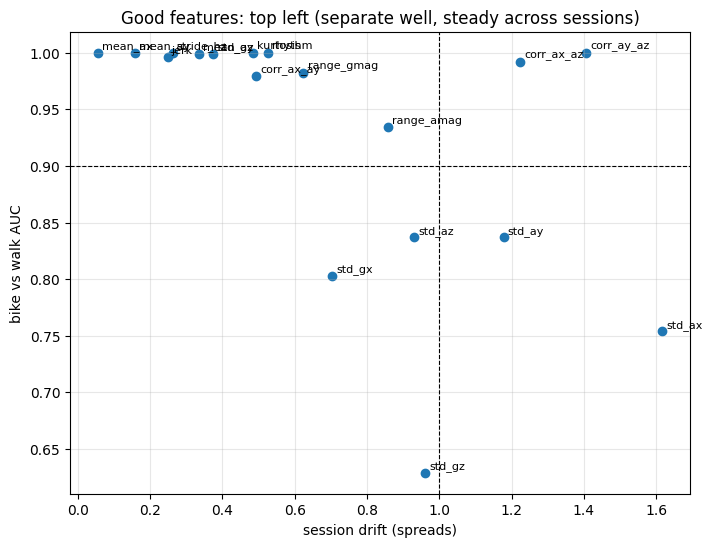

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(rank.session_drift, rank.bike_vs_walk_auc)
for _, r in rank.iterrows():
    ax.annotate(r.feature, (r.session_drift, r.bike_vs_walk_auc), fontsize=8,
                xytext=(3, 3), textcoords="offset points")
ax.axhline(0.9, color="k", ls="--", lw=0.8)
ax.axvline(1.0, color="k", ls="--", lw=0.8)
ax.set_xlabel("session drift (spreads)")
ax.set_ylabel("bike vs walk AUC")
ax.set_title("Good features: top left (separate well, steady across sessions)")
ax.grid(alpha=0.3)